In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("amazon.csv")

anomaly_df = df[
    ['product_id', 'product_name', 'category',
     'actual_price', 'discounted_price',
     'discount_percentage', 'rating',
     'rating_count', 'review_title', 'review_content']
].copy()
anomaly_df['actual_price'] = pd.to_numeric(
    anomaly_df['actual_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

anomaly_df['discounted_price'] = pd.to_numeric(
    anomaly_df['discounted_price'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)
anomaly_df['discount_percentage'] = pd.to_numeric(
    anomaly_df['discount_percentage'].astype(str)
    .str.replace('%', '', regex=False),
    errors='coerce'
)
anomaly_df['rating'] = pd.to_numeric(
    anomaly_df['rating'], errors='coerce'
)
anomaly_df['rating_count'] = pd.to_numeric(
    anomaly_df['rating_count'].astype(str)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

print("Dataset shape:", anomaly_df.shape)
print("\nMissing values:")
print(anomaly_df[
    ['actual_price', 'discounted_price',
     'discount_percentage', 'rating', 'rating_count']
].isnull().sum())

print("\nFeature summary:")
print(anomaly_df[
    ['actual_price', 'discounted_price',
     'discount_percentage', 'rating', 'rating_count']
].describe().round(2))


Dataset shape: (1465, 10)

Missing values:
actual_price           0
discounted_price       0
discount_percentage    0
rating                 1
rating_count           2
dtype: int64

Feature summary:
       actual_price  discounted_price  discount_percentage   rating  \
count       1465.00           1465.00              1465.00  1464.00   
mean        5444.99           3125.31                47.69     4.10   
std        10874.83           6944.30                21.64     0.29   
min           39.00             39.00                 0.00     2.00   
25%          800.00            325.00                32.00     4.00   
50%         1650.00            799.00                50.00     4.10   
75%         4295.00           1999.00                63.00     4.30   
max       139900.00          77990.00                94.00     5.00   

       rating_count  
count       1463.00  
mean       18295.54  
std        42753.86  
min            2.00  
25%         1186.00  
50%         5179.00  
75%    

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'actual_price',
    'discounted_price',
    'discount_percentage',
    'rating',
    'rating_count'
]
iqr_results = []

for col in features:
    values = anomaly_df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (anomaly_df[col] < lower_bound) |
        (anomaly_df[col] > upper_bound)
    )

    iqr_results.append({
        'feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': int(outlier_mask.sum()),
        'outlier_percentage': round(
            outlier_mask.sum() / values.notna().sum() * 100, 2
        )
    })

iqr_summary = pd.DataFrame(iqr_results)

print(iqr_summary.round(2).to_string(index=False))


            feature     Q1      Q3     IQR  lower_bound  upper_bound  outlier_count  outlier_percentage
       actual_price  800.0  4295.0  3495.0     -4442.50      9537.50            213               14.54
   discounted_price  325.0  1999.0  1674.0     -2186.00      4510.00            217               14.81
discount_percentage   32.0    63.0    31.0       -14.50       109.50              0                0.00
             rating    4.0     4.3     0.3         3.55         4.75             74                5.05
       rating_count 1186.0 17336.5 16150.5    -23039.75     41562.25            141                9.64


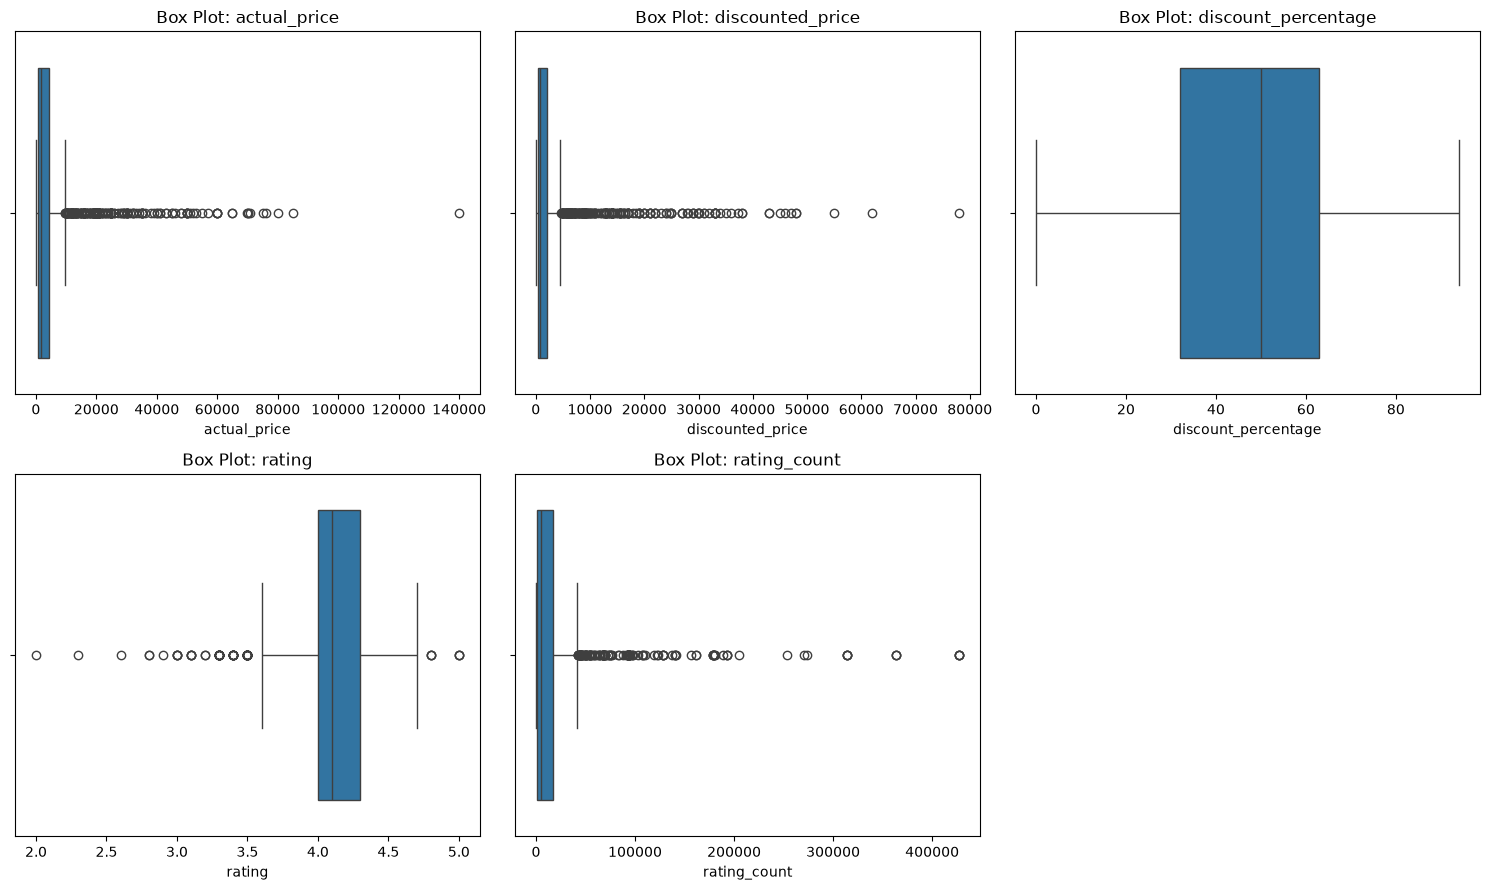

In [3]:

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(x=anomaly_df[col], ax=axes[i])
    axes[i].set_title(f'Box Plot: {col}')
    axes[i].set_xlabel(col)
axes[5].set_visible(False)

plt.tight_layout()
plt.show()


In [4]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
model_features = [
    'actual_price',
    'discounted_price',
    'discount_percentage',
    'rating',
    'rating_count'
]

model_df = anomaly_df.dropna(subset=model_features).copy()
model_df['log_actual_price'] = np.log1p(model_df['actual_price'])
model_df['log_discounted_price'] = np.log1p(
    model_df['discounted_price']
)
model_df['log_rating_count'] = np.log1p(
    model_df['rating_count']
)

features_for_model = [
    'log_actual_price',
    'log_discounted_price',
    'discount_percentage',
    'rating',
    'log_rating_count'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(model_df[features_for_model])

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

predictions = iso_forest.fit_predict(X_scaled)
model_df['isolation_anomaly'] = predictions == -1
model_df['anomaly_score'] = -iso_forest.decision_function(X_scaled)

print("Records analyzed:", len(model_df))
print("Isolation Forest anomalies:",
      int(model_df['isolation_anomaly'].sum()))
print("Anomaly percentage:",
      round(model_df['isolation_anomaly'].mean() * 100, 2), "%")


Records analyzed: 1462
Isolation Forest anomalies: 74
Anomaly percentage: 5.06 %


In [5]:

iqr_flags = pd.DataFrame(index=model_df.index)

for col in model_features:
    q1 = model_df[col].quantile(0.25)
    q3 = model_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_flags[col] = (
        (model_df[col] < lower) |
        (model_df[col] > upper)
    )

model_df['iqr_anomaly'] = iqr_flags.any(axis=1)

comparison = pd.crosstab(
    model_df['iqr_anomaly'],
    model_df['isolation_anomaly'],
    rownames=['IQR anomaly'],
    colnames=['Isolation Forest anomaly']
)

print("Method comparison:")
print(comparison)

both_methods = (
    model_df['iqr_anomaly'] &
    model_df['isolation_anomaly']
).sum()

print("\nDetected by both methods:", int(both_methods))
print("IQR anomalies:", int(model_df['iqr_anomaly'].sum()))
print("Isolation Forest anomalies:",
      int(model_df['isolation_anomaly'].sum()))


Method comparison:
Isolation Forest anomaly  False  True 
IQR anomaly                           
False                      1005     24
True                        383     50

Detected by both methods: 50
IQR anomalies: 433
Isolation Forest anomalies: 74


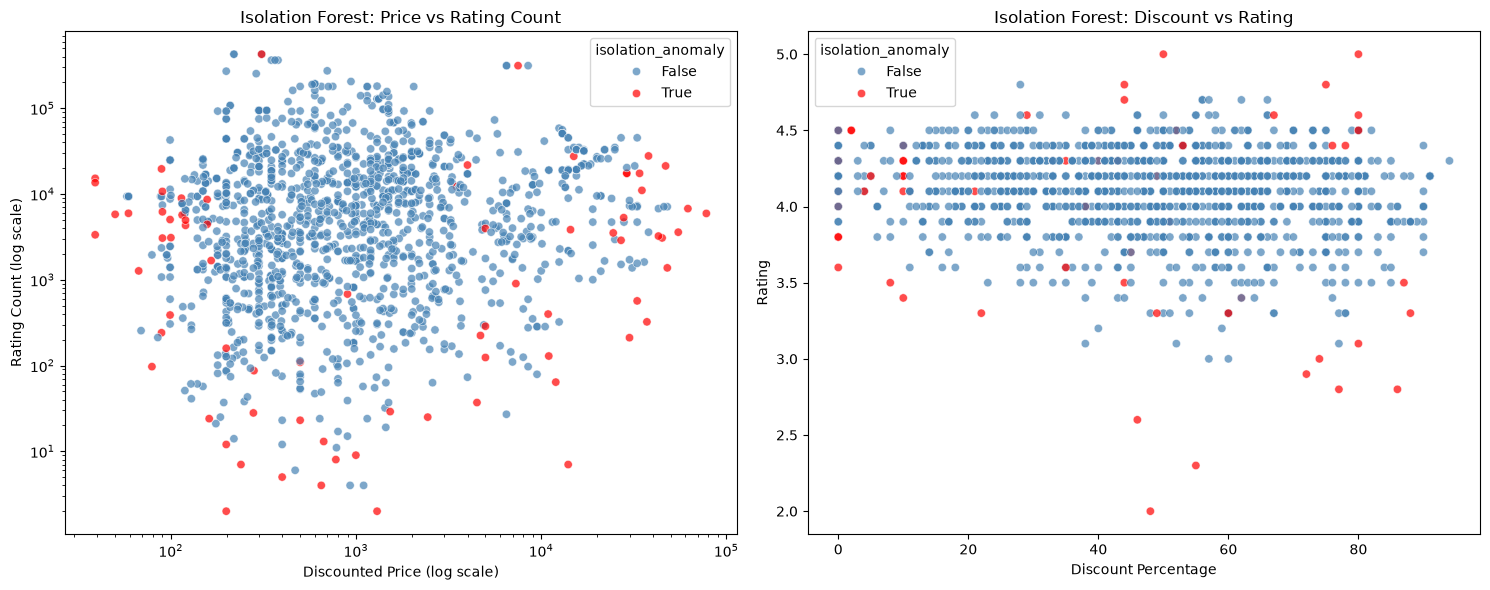

In [6]:

model_df['main_category'] = model_df['category'].str.split('|').str[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(
    data=model_df,
    x='discounted_price',
    y='rating_count',
    hue='isolation_anomaly',
    palette={False: 'steelblue', True: 'red'},
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Isolation Forest: Price vs Rating Count')
axes[0].set_xlabel('Discounted Price (log scale)')
axes[0].set_ylabel('Rating Count (log scale)')

sns.scatterplot(
    data=model_df,
    x='discount_percentage',
    y='rating',
    hue='isolation_anomaly',
    palette={False: 'steelblue', True: 'red'},
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title('Isolation Forest: Discount vs Rating')
axes[1].set_xlabel('Discount Percentage')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()


In [7]:

top_anomalies = model_df[
    model_df['isolation_anomaly']
].sort_values(
    'anomaly_score',
    ascending=False
).head(15).copy()
for col in ['review_title', 'review_content']:
    top_anomalies[col] = (
        top_anomalies[col].fillna('').astype(str).str.slice(0, 250)
    )

display_columns = [
    'product_id',
    'product_name',
    'main_category',
    'actual_price',
    'discounted_price',
    'discount_percentage',
    'rating',
    'rating_count',
    'anomaly_score',
    'review_title',
    'review_content'
]

print(top_anomalies[display_columns].to_string(index=False))


product_id                                                                                                                                                                                             product_name         main_category  actual_price  discounted_price  discount_percentage  rating  rating_count  anomaly_score                                                                                                                                                                                                                                               review_title                                                                                                                                                                                                                                             review_content
B00URH5E34                                                                                                                                  Inventis 5V 1.2W Portable Flexible

In [8]:

investigation = top_anomalies[
    [
        'product_id', 'product_name', 'main_category',
        'actual_price', 'discounted_price',
        'discount_percentage', 'rating', 'rating_count',
        'iqr_anomaly', 'isolation_anomaly',
        'anomaly_score', 'review_title', 'review_content'
    ]
].copy()

investigation.to_csv(
    'task5_anomaly_investigation.csv',
    index=False
)

print("Saved task5_anomaly_investigation.csv")
display(investigation)


Saved task5_anomaly_investigation.csv


,product_id,product_name,main_category,actual_price,discounted_price,discount_percentage,rating,rating_count,iqr_anomaly,isolation_anomaly,anomaly_score,review_title,review_content
997,B00URH5E34,Inventis 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories,39.0,39.0,0,3.6,13572.0,False,True,0.127745,"it worked properly for almost one year,ok,USB ...","very good product, very bright, easy to use, i..."
975,B08TDJ5BVF,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories,39.0,39.0,0,3.8,3344.0,False,True,0.113534,"Lighting,TINY & USEFUL.,Fair product,Worth for...","Recieved a wrong color.. But ok..,Simple and Q..."
710,B08TDJNM3G,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories,59.0,59.0,0,3.8,5958.0,False,True,0.094336,"Good,Product as described,Good for the price,V...","Good,Product is as described, good we can use ..."
616,B07KCMR8D6,Classmate Octane Neon- Blue Gel Pens(Pack of 5...,OfficeProducts,50.0,50.0,0,4.3,5792.0,False,True,0.085072,"Nice ball pen,Good product,Average,Nice Pen,It...","Very nice ball pen,Thank you Amazon,Easy to ho..."
1309,B0BPJBTB3F,Khaitan ORFin Fan heater for Home and kitchen-...,Home&Kitchen,2495.0,1299.0,48,2.0,2.0,True,True,0.082420,"Bad quality,Amazing product..",The heating capacity is zero .Moreover i have ...
1459,B0B3JSWG81,NGI Store 2 Pieces Pet Hair Removers for Your ...,Home&Kitchen,999.0,199.0,80,3.1,2.0,True,True,0.081761,Useless,Does not work as advertised at all. The pieces...
1165,B0B4PPD89B,Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...,Home&Kitchen,79.0,79.0,0,4.0,97.0,False,True,0.080681,"Good clips.,Second quality,Value for money.,No...",I bought it for ₹79. Don't think that because ...
1356,B0B7L86YCB,Green Tales Heat Seal Mini Food Sealer-Impulse...,Home&Kitchen,300.0,161.0,46,2.6,24.0,True,True,0.079347,"It is broken,Could have been a bit better,The ...",It is broken and it is not useful. Please chan...
249,B09WN3SRC7,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,Electronics,139900.0,77990.0,44,4.7,5935.0,True,True,0.068605,Product installation was excellent but delive...,The delivery people were not careful with the ...
174,B0BP7XLX48,Syncwire LTG to USB Cable for Fast Charging Co...,Computers&Accessories,1999.0,399.0,80,5.0,5.0,True,True,0.065139,"Good,Superb quality,Good products nice one,Wo...",Product is good in quality. Working good with ...
